# IA102 — Notebook 1 — Introduction aux réseaux de neurones

**Durée : 30 minutes** · Objectifs visés : **O1** (bases de l'apprentissage profond) et **O2** (créer des réseaux)

### Plan
1. Le neurone artificiel
2. Les fonctions d'activation
3. Des neurones aux couches, des couches aux réseaux
4. Les tenseurs PyTorch
5. Autograd et rétropropagation
6. Définir un réseau : `nn.Sequential` et `nn.Module`
7. Couche de sortie et fonction de perte

In [1]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(0)

## 1. Le neurone artificiel

Un neurone reçoit un vecteur d'entrées $x = (x_1, \dots, x_d)$, calcule une **combinaison linéaire** pondérée par des **poids** $w$ et décalée par un **biais** $b$, puis applique une **fonction d'activation** $\varphi$ :

$$z = w^\top x + b = \sum_{j=1}^{d} w_j\,x_j + b \qquad\qquad a = \varphi(z)$$

Les poids et le biais sont les **paramètres** du neurone. Sans activation (ou avec l'identité), un neurone est exactement une régression linéaire ; avec la sigmoïde, c'est une régression logistique (IA101, notebook 3).

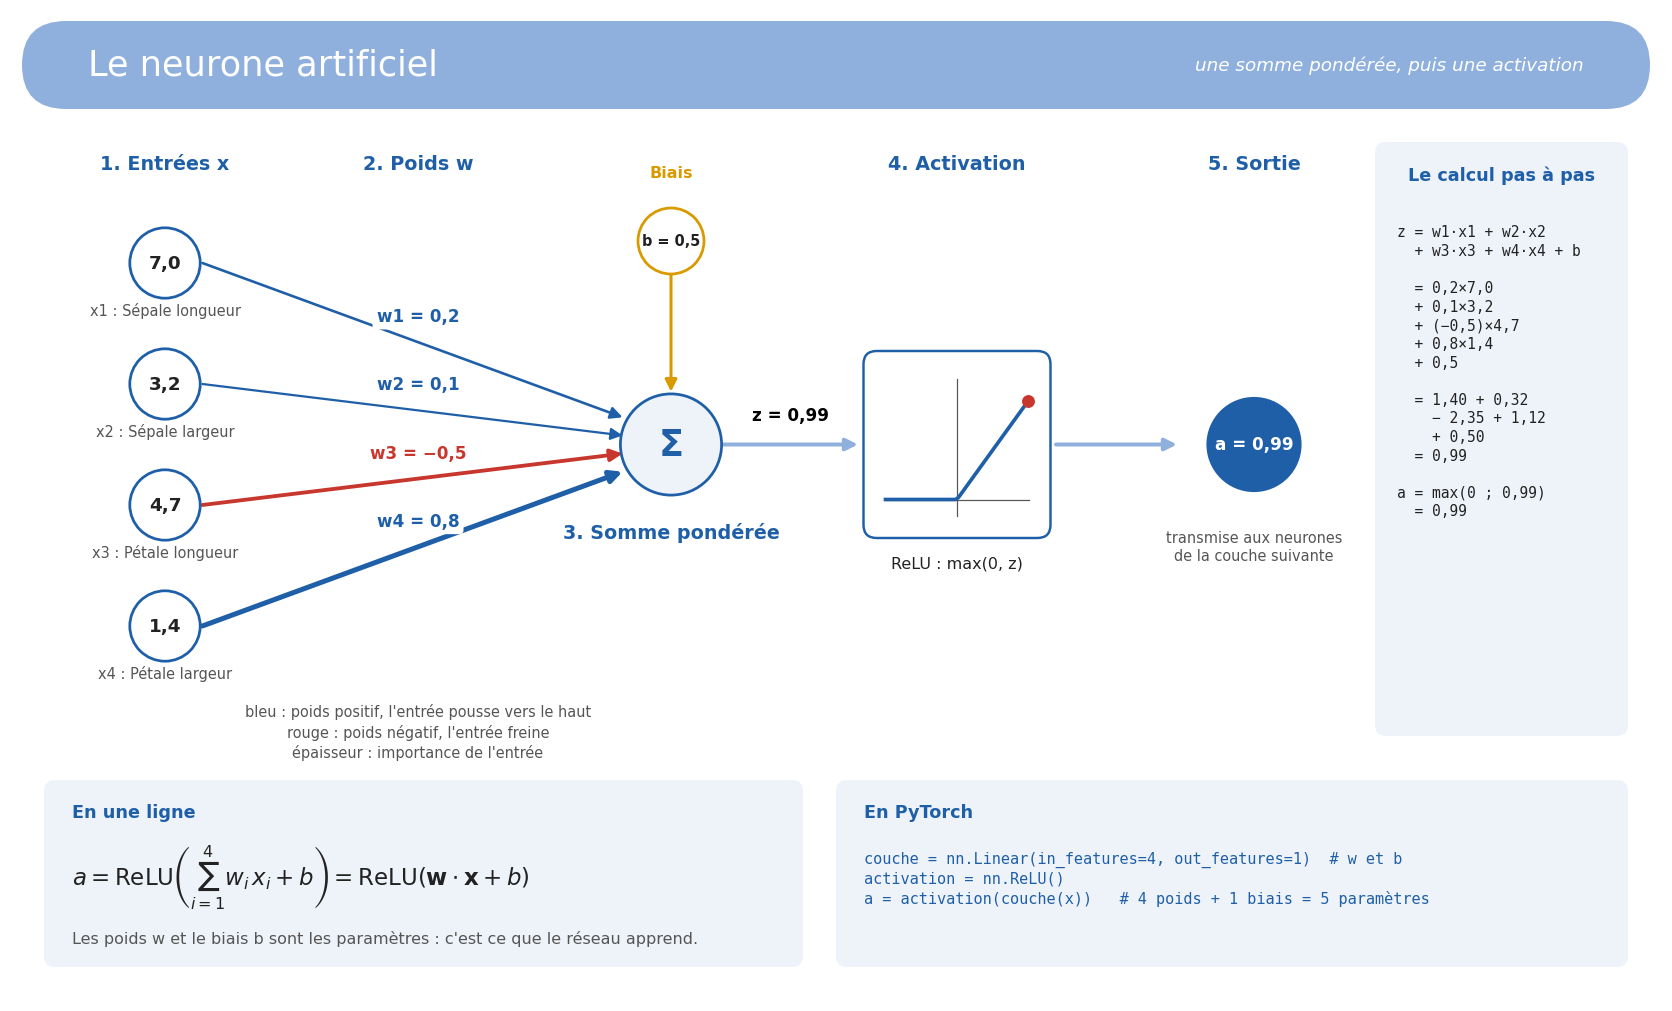

In [4]:
#@title
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
ROUGE, JAUNE = "#c8372d", "#d99a00"


def nombre(v, dec=2):
    """Nombre au format français : virgule décimale et vrai signe moins."""
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def fleche(ax, depart, arrivee, couleur=BLEU_CLAIR, lw=2.2):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle="-|>", mutation_scale=16,
                                 color=couleur, lw=lw, shrinkA=0, shrinkB=0, zorder=2))


def cercle(ax, x, y, r, texte="", fc="white", ec=BLEU, couleur_texte=ENCRE, taille=11):
    ax.add_patch(Circle((x, y), r, fc=fc, ec=ec, lw=1.8, zorder=4))
    ax.text(x, y, texte, ha="center", va="center", fontsize=taille, fontweight="bold",
            color=couleur_texte, zorder=5)


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


# Exemple numérique : une fleur d'iris (versicolor), ses 4 mesures en cm
noms = ["Sépale longueur", "Sépale largeur", "Pétale longueur", "Pétale largeur"]
x = np.array([7.0, 3.2, 4.7, 1.4])      # entrées
w = np.array([0.2, 0.1, -0.5, 0.8])     # poids (choisis pour l'exemple)
b = 0.5                                 # biais
z = float(x @ w + b)                    # somme pondérée
a = max(z, 0.0)                         # activation ReLU

fig = plt.figure(figsize=(15, 9))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 150); ax.set_ylim(0, 90); ax.axis("off")

# Bandeau de titre
ax.add_patch(FancyBboxPatch((1, 81), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
ax.text(7, 85, "Le neurone artificiel", color="white", fontsize=23, va="center")
ax.text(143, 85, "une somme pondérée, puis une activation", color="white", fontsize=12,
        va="center", ha="right", style="italic")

# 1. Entrées : les 4 mesures de la fleur
ys = [67, 56, 45, 34]
ax.text(14, 75.5, "1. Entrées x", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
for i, (yy, nom, xi) in enumerate(zip(ys, noms, x)):
    cercle(ax, 14, yy, 3.2, nombre(xi, 1), taille=12)
    ax.text(14, yy - 4.7, f"x{i + 1} : {nom}", ha="center", fontsize=9.5, color=GRIS)

# 2. Poids : couleur = signe, épaisseur = importance
xs, ys_sigma = 60, 50.5
ax.text(37, 75.5, "2. Poids w", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
for i, (yy, wi) in enumerate(zip(ys, w)):
    c = BLEU if wi > 0 else ROUGE
    y_fin = ys_sigma + (yy - ys_sigma) * .15
    fleche(ax, (17.4, yy), (xs - 4.4, y_fin), couleur=c, lw=1.2 + 2.6 * abs(wi))
    y_milieu = yy + (y_fin - yy) * (37 - 17.4) / (xs - 4.4 - 17.4)
    ax.text(37, y_milieu + 1.9, f"w{i + 1} = {nombre(wi, 1)}", ha="center", fontsize=11, color=c,
            fontweight="bold", bbox=dict(boxstyle="round,pad=.25", fc="white", ec="none"), zorder=6)
ax.text(37, 27, "bleu : poids positif, l'entrée pousse vers le haut\n"
                "rouge : poids négatif, l'entrée freine\n"
                "épaisseur : importance de l'entrée",
        ha="center", va="top", fontsize=9.5, color=GRIS, linespacing=1.35)

# Biais
cercle(ax, xs, 69, 3, f"b = {nombre(b, 1)}", ec=JAUNE, taille=9.5)
ax.text(xs, 74.8, "Biais", ha="center", fontsize=10.5, fontweight="bold", color=JAUNE)
fleche(ax, (xs, 66), (xs, ys_sigma + 4.8), couleur=JAUNE, lw=2)

# 3. Somme pondérée
cercle(ax, xs, ys_sigma, 4.6, "Σ", fc=FOND, couleur_texte=BLEU, taille=24)
ax.text(xs, ys_sigma - 8.5, "3. Somme pondérée", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
fleche(ax, (xs + 4.8, ys_sigma), (77, ys_sigma), lw=2.6)
ax.text(70.9, ys_sigma + 2.2, f"z = {nombre(z)}", ha="center", fontsize=11, fontweight="bold")

# 4. Activation ReLU (petit graphique, avec la valeur de z en rouge)
ax.text(86, 75.5, "4. Activation", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
ax.add_patch(FancyBboxPatch((77.5, ys_sigma - 8.5), 17, 17, boxstyle="round,pad=0,rounding_size=1.2",
                            fc="white", ec=BLEU, lw=1.6, zorder=3))
zr = np.linspace(-1, 1, 50)
x0, y0 = 79.5, ys_sigma - 5
ax.plot(x0 + (zr + 1) * 6.5, y0 + np.maximum(zr, 0) * 9, color=BLEU, lw=2.4, zorder=5)
ax.plot([x0, x0 + 13], [y0, y0], color=GRIS, lw=.8, zorder=4)
ax.plot([x0 + 6.5, x0 + 6.5], [y0 - 1.5, y0 + 11], color=GRIS, lw=.8, zorder=4)
zc = min(max(z, -1), 1)
ax.scatter([x0 + (zc + 1) * 6.5], [y0 + max(zc, 0) * 9], s=55, color=ROUGE, zorder=6)
ax.text(86, ys_sigma - 11.2, "ReLU : max(0, z)", ha="center", fontsize=10.5, color=ENCRE)
fleche(ax, (95, ys_sigma), (106, ys_sigma), lw=2.6)

# 5. Sortie
ax.text(113, 75.5, "5. Sortie", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
cercle(ax, 113, ys_sigma, 4.2, f"a = {nombre(a)}", fc=BLEU, ec=BLEU, couleur_texte="white")
ax.text(113, ys_sigma - 7.8, "transmise aux neurones\nde la couche suivante", ha="center", va="top",
        fontsize=9.5, color=GRIS)

# Encadré : le calcul pas à pas
encadre(ax, 124, 24, 23, 54)
ax.text(135.5, 74.5, "Le calcul pas à pas", ha="center", fontsize=11.5, fontweight="bold", color=BLEU)
produits = w * x
lignes = ["z = w1·x1 + w2·x2", "  + w3·x3 + w4·x4 + b", ""]
lignes += [f"  {'=' if i == 0 else '+'} {'(' + nombre(wi, 1) + ')' if wi < 0 else nombre(wi, 1)}×{nombre(xi, 1)}"
           for i, (wi, xi) in enumerate(zip(w, x))]
lignes += [f"  + {nombre(b, 1)}", ""]
lignes += [f"  = {nombre(produits[0])} + {nombre(produits[1])}",
           f"    − {nombre(-produits[2])} + {nombre(produits[3])}",
           f"    + {nombre(b)}",
           f"  = {nombre(z)}", "", f"a = max(0 ; {nombre(z)})", f"  = {nombre(a)}"]
ax.text(126, 70.5, "\n".join(lignes), fontsize=9.6, va="top", family="monospace", color=ENCRE, linespacing=1.3)

# Bas : formule et code PyTorch
encadre(ax, 3, 3, 69, 17)
ax.text(5.5, 16.6, "En une ligne", fontsize=11.5, fontweight="bold", color=BLEU)
ax.text(5.5, 11.2, r"$a = \mathrm{ReLU}\left(\sum_{i=1}^{4} w_i\,x_i + b\right) = \mathrm{ReLU}(\mathbf{w}\cdot\mathbf{x} + b)$",
        fontsize=15, color=ENCRE, va="center")
ax.text(5.5, 5.6, "Les poids w et le biais b sont les paramètres : c'est ce que le réseau apprend.",
        fontsize=10.5, color=GRIS, va="center")
encadre(ax, 75, 3, 72, 17)
ax.text(77.5, 16.6, "En PyTorch", fontsize=11.5, fontweight="bold", color=BLEU)
ax.text(77.5, 13.6, "couche = nn.Linear(in_features=4, out_features=1)  # w et b\n"
                    "activation = nn.ReLU()\n"
                    "a = activation(couche(x))   # 4 poids + 1 biais = 5 paramètres",
        family="monospace", fontsize=10, color=BLEU, va="top", linespacing=1.35)

plt.savefig("fig1_neurone.png", dpi=170, facecolor="white")
plt.show()

### Exercice 1 — Calculer la sortie d'un neurone

Avec les valeurs du schéma, calculez $z$, puis $a = \text{ReLU}(z) = \max(z, 0)$. Faites d'abord le calcul à la main.

In [ ]:
x = np.array([2.0, -1.0, 0.5])
w = np.array([0.4, 0.3, -0.6])
b = 0.1

z = ...   # À COMPLÉTER avec np.dot(..., ...) + ...
a = ...   # À COMPLÉTER avec max(..., ...)
print(f"z = {z:.2f}, a = {a:.2f}")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
x = np.array([2.0, -1.0, 0.5])
w = np.array([0.4, 0.3, -0.6])
b = 0.1

z = np.dot(w, x) + b          # 0,8 − 0,3 − 0,3 + 0,1 = 0,3
a = max(z, 0)
print(f"z = {z:.2f}, a = {a:.2f}")
```

</details>

Vérification avec PyTorch : `nn.Linear(3, 1)` implémente exactement $z = w^\top x + b$.

`nn.Linear(3, 1)` est un neurone à 3 entrées : `weight` (forme `(1, 3)`) correspond à $\mathbf{w}$ et `bias` à $b$. On lui impose $\mathbf{w} = (0.4,\ 0.3,\ -0.6)$ et $b = 0.1$, en passant par `torch.no_grad()` puisque les paramètres suivent les gradients. On compare ensuite avec le calcul à la main :

$$z = 0.4 \times 2 + 0.3 \times (-1) - 0.6 \times 0.5 + 0.1 = 0.3 \qquad a = \text{ReLU}(z) = 0.3$$

In [13]:
neurone = nn.Linear(3, 1)
with torch.no_grad():
    neurone.weight[:] = torch.tensor([[0.4, 0.3, -0.6]])
    neurone.bias[:] = torch.tensor([0.1])
z_torch = neurone(torch.tensor([2.0, -1.0, 0.5]))
print("z (PyTorch) :", round(z_torch.item(), 4), "| a = ReLU(z) :", round(torch.relu(z_torch).item(), 4))

z (PyTorch) : 0.3 | a = ReLU(z) : 0.3


## 2. Les fonctions d'activation

Une **fonction d'activation** $\sigma$ est une fonction non linéaire (ReLU, sigmoïde, tanh…) appliquée à la sortie linéaire $z = Wx + b$ de chaque couche. Sans elle, un empilement de couches resterait équivalent à un seul modèle linéaire, puisqu'une composition de transformations linéaires est encore linéaire. Avec elle, le réseau peut apprendre des relations et des **frontières de décision non linéaires**.

| Activation | &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Formule&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp; | Usage principal |
| ------ | :------------: | ------ |
| ReLU | $\max(0, z)$ | Couches cachées (choix par défaut) |
| Sigmoïde | $1 / (1 + e^{-z})$ | Probabilité d'une classe binaire |
| Tanh | $(e^{z} - e^{-z}) / (e^{z} + e^{-z})$ | Sorties centrées entre −1 et 1 |
| Softmax | $e^{z_k} / \sum_j e^{z_j}$ | Probabilités de plusieurs classes |

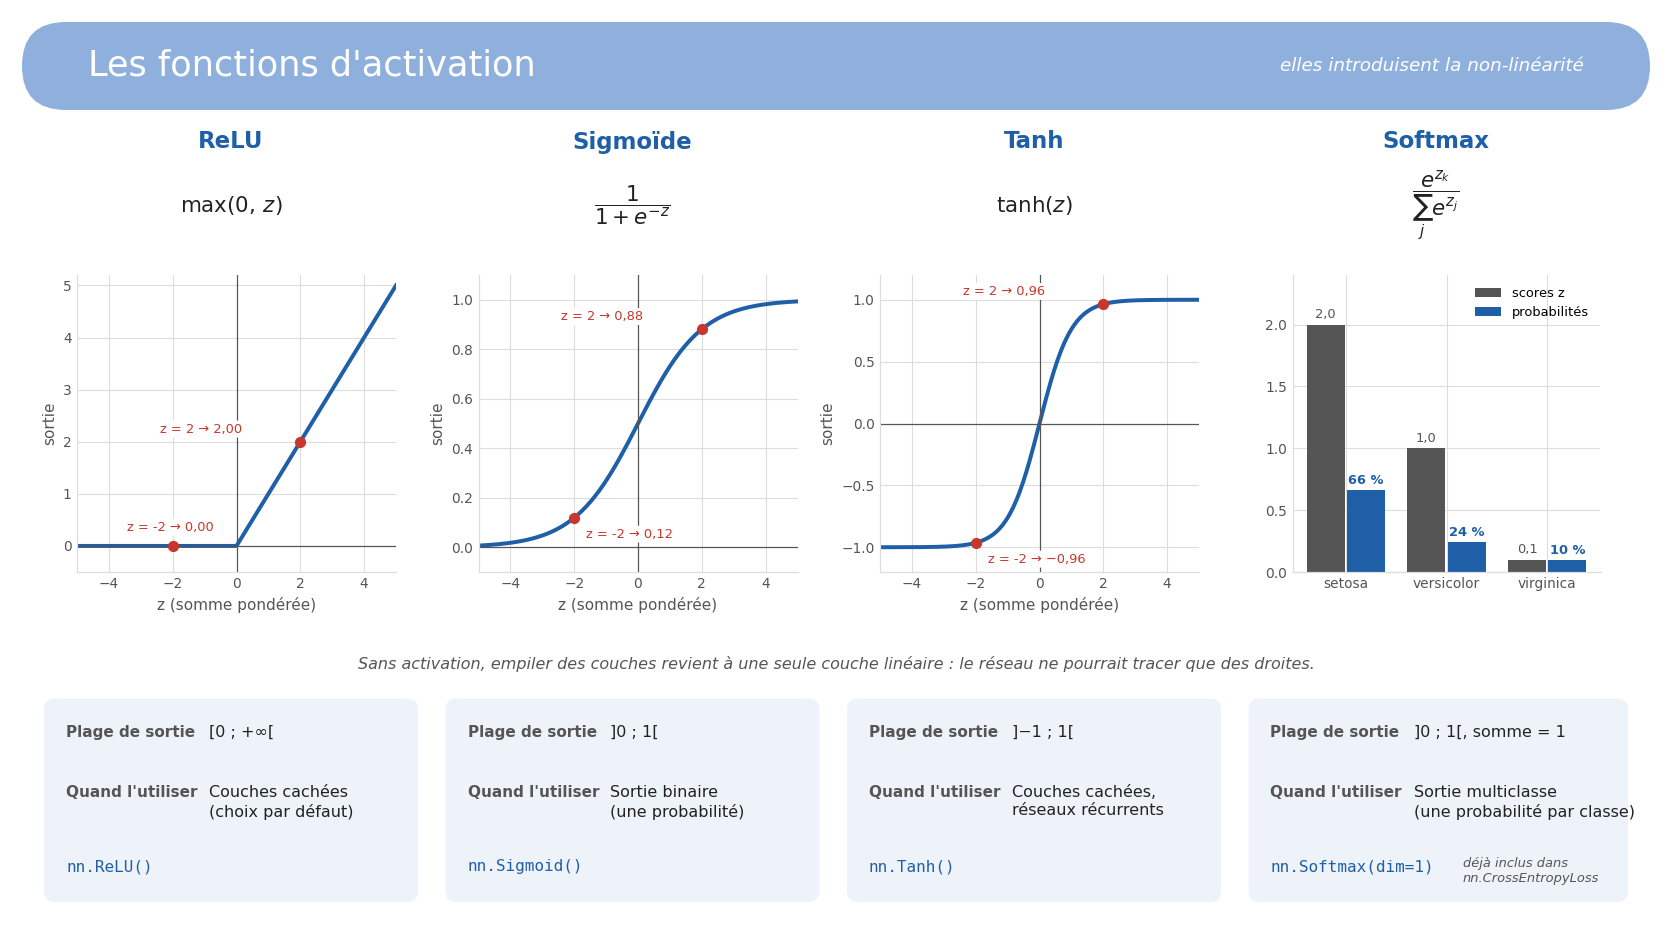

In [5]:
# @title
from matplotlib.patches import FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS, GRILLE = "#222222", "#555555", "#dddddd"
BLEU, BLEU_CLAIR, FOND, ROUGE = "#1f5fa8", "#8fb0dd", "#eef3fa", "#c8372d"


def nombre(v, dec=2):
    """Nombre au format français : virgule décimale et vrai signe moins."""
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


def style_axes(ax, xlabel="", ylabel=""):
    """Axes discrets : grille légère, pas de bordure en haut ni à droite."""
    ax.set_xlabel(xlabel, fontsize=10, color=GRIS); ax.set_ylabel(ylabel, fontsize=10, color=GRIS)
    ax.tick_params(colors=GRIS, labelsize=9, length=0)
    ax.grid(color=GRILLE, lw=.7); ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)
    for cote in ("left", "bottom"):
        ax.spines[cote].set_color(GRILLE)


def fiche(ax, x0, l, plage, usage, code_pt, note=None):
    """Encadré sous chaque graphique : plage de sortie, usage et code PyTorch."""
    encadre(ax, x0, 3, l, 18.5)
    ax.text(x0 + 2, 18, "Plage de sortie", fontsize=10, fontweight="bold", color=GRIS)
    ax.text(x0 + 15, 18, plage, fontsize=10.5, color=ENCRE)
    ax.text(x0 + 2, 13.6, "Quand l'utiliser", fontsize=10, fontweight="bold", color=GRIS, va="top")
    ax.text(x0 + 15, 13.6, usage, fontsize=10.5, color=ENCRE, va="top", linespacing=1.25)
    ax.text(x0 + 2, 5.8, code_pt, family="monospace", fontsize=10.5, color=BLEU)
    if note:
        ax.text(x0 + 19.5, 5.8, note, fontsize=8.5, color=GRIS, va="center", style="italic")


# Fond de la figure, en coordonnées 0..150 × 0..84
fig = plt.figure(figsize=(15, 8.4))
fond = fig.add_axes([0, 0, 1, 1], zorder=-1)
fond.set_xlim(0, 150); fond.set_ylim(0, 84); fond.axis("off")
fond.add_patch(FancyBboxPatch((1, 75), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
fond.text(7, 79, "Les fonctions d'activation", color="white", fontsize=23, va="center")
fond.text(143, 79, "elles introduisent la non-linéarité", color="white", fontsize=12,
          va="center", ha="right", style="italic")

# ReLU, sigmoïde et tanh : courbe, deux points d'exemple et fiche
zs = np.linspace(-5, 5, 300)
fonctions = [  # (nom, fonction, formule, plage, usage, code, limites de l'axe y)
    ("ReLU", lambda z: np.maximum(z, 0), r"$\max(0,\, z)$", "[0 ; +∞[",
     "Couches cachées\n(choix par défaut)", "nn.ReLU()", (-0.5, 5.2)),
    ("Sigmoïde", lambda z: 1 / (1 + np.exp(-z)), r"$\dfrac{1}{1 + e^{-z}}$", "]0 ; 1[",
     "Sortie binaire\n(une probabilité)", "nn.Sigmoid()", (-0.1, 1.1)),
    ("Tanh", np.tanh, r"$\tanh(z)$", "]−1 ; 1[",
     "Couches cachées,\nréseaux récurrents", "nn.Tanh()", (-1.2, 1.2)),
]
for k, (nom, fn, formule, plage, usage, code_pt, ylim) in enumerate(fonctions):
    x0 = 3 + k * 36.5
    fond.text(x0 + 17, 71.5, nom, ha="center", fontsize=15, fontweight="bold", color=BLEU)
    fond.text(x0 + 17, 66.3, formule, ha="center", fontsize=14, color=ENCRE, va="center")

    ax = fig.add_axes([(x0 + 3) / 150, 33 / 84, 29 / 150, 27 / 84])
    ax.plot(zs, fn(zs), color=BLEU, lw=2.6)
    ax.axhline(0, color=GRIS, lw=.8); ax.axvline(0, color=GRIS, lw=.8)
    ax.set_xlim(-5, 5); ax.set_ylim(*ylim)
    style_axes(ax, "z (somme pondérée)", "sortie")

    # Deux exemples : z = −2 et z = 2
    for zz in (-2, 2):
        ax.scatter([zz], [fn(zz)], s=40, color=ROUGE, zorder=4)
        decalage = ((-30, 10) if nom == "ReLU" else (8, -13)) if zz < 0 else (-92, 6)
        ax.annotate(f"z = {zz} → {nombre(float(fn(zz)))}", (zz, fn(zz)), textcoords="offset points",
                    xytext=decalage, fontsize=8.5, color=ROUGE, zorder=5,
                    bbox=dict(boxstyle="round,pad=.15", fc="white", ec="none"))

    fiche(fond, x0, 34, plage, usage, code_pt)

# Softmax : transforme 3 scores en 3 probabilités dont la somme vaut 1
x0 = 112.5
fond.text(x0 + 17, 71.5, "Softmax", ha="center", fontsize=15, fontweight="bold", color=BLEU)
fond.text(x0 + 17, 66.3, r"$\dfrac{e^{z_k}}{\sum_j e^{z_j}}$", ha="center", fontsize=14, color=ENCRE, va="center")
scores = np.array([2.0, 1.0, 0.1])
probs = np.exp(scores) / np.exp(scores).sum()
classes = ["setosa", "versicolor", "virginica"]

ax = fig.add_axes([(x0 + 4) / 150, 33 / 84, 28 / 150, 27 / 84])
pos = np.arange(3)
ax.bar(pos - .2, scores, .38, color=GRIS, label="scores z")
ax.bar(pos + .2, probs, .38, color=BLEU, label="probabilités")
for p, s, pr in zip(pos, scores, probs):
    ax.text(p - .2, s + .05, nombre(s, 1), ha="center", fontsize=8.5, color=GRIS)
    ax.text(p + .2, pr + .05, f"{pr * 100:.0f} %", ha="center", fontsize=8.5, color=BLEU, fontweight="bold")
ax.set_xticks(pos, classes); ax.set_ylim(0, 2.4)
style_axes(ax); ax.legend(frameon=False, fontsize=8.5, loc="upper right")

fiche(fond, x0, 34.5, "]0 ; 1[, somme = 1", "Sortie multiclasse\n(une probabilité par classe)",
      "nn.Softmax(dim=1)", note="déjà inclus dans\nnn.CrossEntropyLoss")

fond.text(75, 24.2, "Sans activation, empiler des couches revient à une seule couche linéaire : "
                    "le réseau ne pourrait tracer que des droites.",
          ha="center", fontsize=10.5, style="italic", color=GRIS)

plt.savefig("fig2_activations.png", dpi=170, facecolor="white")
plt.show()

**Pourquoi la non-linéarité est indispensable.** Une composition de fonctions affines est encore une fonction affine : $W_2(W_1 x + b_1) + b_2 = (W_2 W_1)\,x + (W_2 b_1 + b_2)$. Sans activation non linéaire, un réseau de 100 couches équivaut à une seule couche linéaire.

**Prédiction.** Deux couches linéaires sans activation peuvent-elles produire autre chose qu'une droite ?

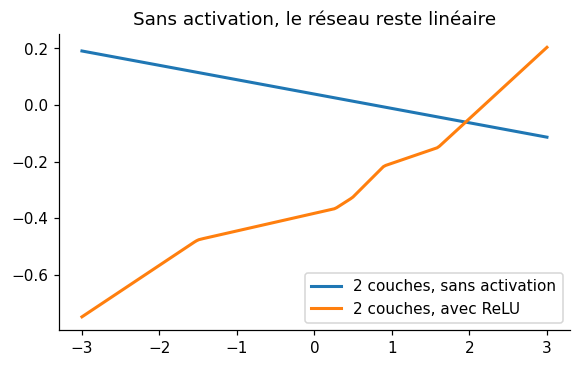

In [6]:
torch.manual_seed(1)
sans_activation = nn.Sequential(nn.Linear(1, 8), nn.Linear(8, 1))
avec_relu = nn.Sequential(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1))
xs = torch.linspace(-3, 3, 200).unsqueeze(1)
with torch.no_grad():
    plt.figure(figsize=(6, 3.5))
    plt.plot(xs, sans_activation(xs), lw=2, label="2 couches, sans activation")
    plt.plot(xs, avec_relu(xs), lw=2, label="2 couches, avec ReLU")
plt.title("Sans activation, le réseau reste linéaire"); plt.legend(); plt.show()

## 3. Des neurones aux couches, des couches aux réseaux

Une **couche** applique plusieurs neurones en parallèle aux mêmes entrées. Sous forme matricielle, pour une couche de $m$ neurones et un lot de $n$ observations :

$$Z = X\,W^\top + b \qquad X \in \mathbb{R}^{n \times d},\; W \in \mathbb{R}^{m \times d},\; Z \in \mathbb{R}^{n \times m}$$

Un **réseau multicouche** enchaîne des couches : chaque couche transforme la représentation produite par la précédente. Les couches intermédiaires sont dites **cachées**.

Le **théorème d'approximation universelle** établit qu'un réseau à une couche cachée suffisamment large peut approcher toute fonction continue sur un domaine borné. En pratique, les réseaux **profonds** (plusieurs couches) obtiennent les mêmes capacités avec beaucoup moins de paramètres, en construisant des représentations hiérarchiques.


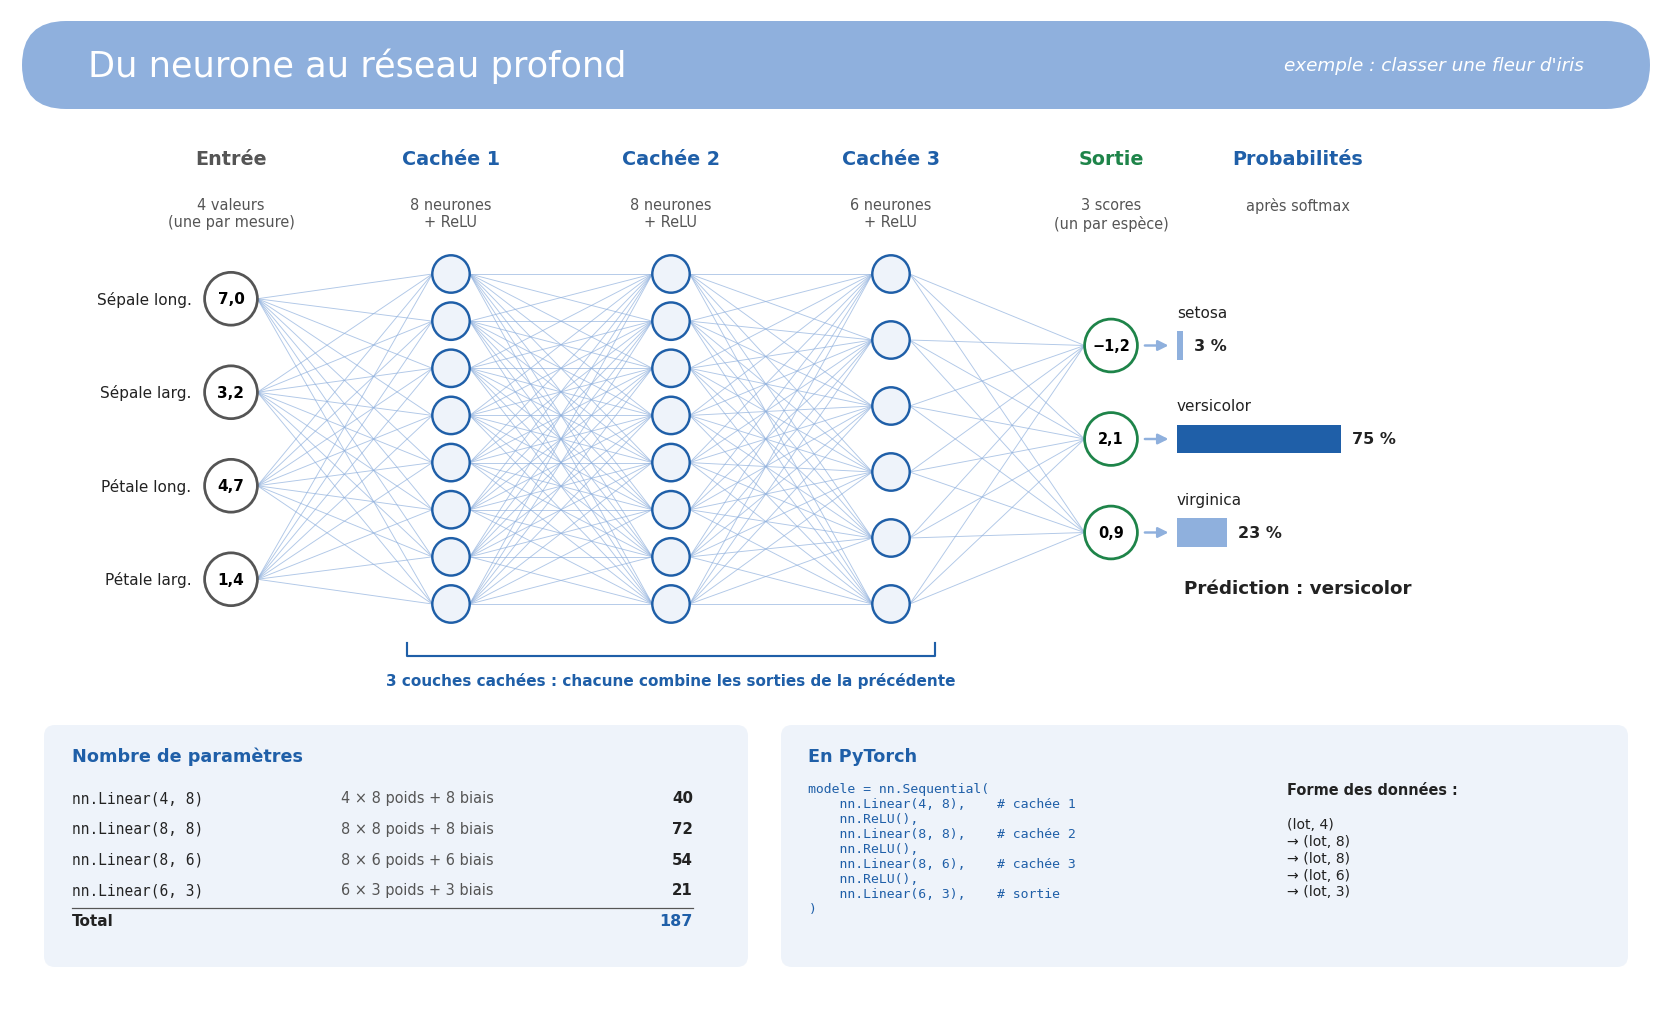

In [7]:
# @title
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND, VERT = "#1f5fa8", "#8fb0dd", "#eef3fa", "#1e8449"


def nombre(v, dec=2):
    """Nombre au format français : virgule décimale et vrai signe moins."""
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def encadre(ax, x, y, l, h):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=FOND, ec="none", zorder=1))


# Architecture : modifiez cette liste pour changer le réseau (entrée, couches cachées..., sortie)
tailles = [4, 8, 8, 6, 3]
n_cachees = len(tailles) - 2

# Une fleur d'iris (versicolor) et des scores de sortie choisis pour l'exemple
entrees = ["Sépale long.", "Sépale larg.", "Pétale long.", "Pétale larg."]
valeurs = [7.0, 3.2, 4.7, 1.4]
classes = ["setosa", "versicolor", "virginica"]
scores = np.array([-1.2, 2.1, 0.9])
probs = np.exp(scores) / np.exp(scores).sum()

fig = plt.figure(figsize=(15, 9))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 150); ax.set_ylim(0, 90); ax.axis("off")

# Bandeau de titre
ax.add_patch(FancyBboxPatch((1, 81), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
ax.text(7, 85, "Du neurone au réseau profond", color="white", fontsize=23, va="center")
ax.text(143, 85, "exemple : classer une fleur d'iris", color="white", fontsize=12,
        va="center", ha="right", style="italic")

# Position de chaque couche : x régulièrement espacés, neurones centrés verticalement
xs = np.linspace(20, 100, len(tailles))
centre_y, hauteur_max = 51, 30


def positions(n):
    ecart = min(hauteur_max / max(n - 1, 1), 8.5)
    return [centre_y + (i - (n - 1) / 2) * ecart for i in range(n)][::-1]


def rayon(k):
    return 2.4 if k in (0, len(tailles) - 1) else 1.7


# Connexions entre couches voisines (une ligne par poids)
for k in range(len(tailles) - 1):
    for y1 in positions(tailles[k]):
        for y2 in positions(tailles[k + 1]):
            ax.plot([xs[k] + rayon(k), xs[k + 1] - rayon(k + 1)], [y1, y2],
                    color=BLEU_CLAIR, lw=.6, alpha=.7, zorder=2)

# Neurones
for k, (x, n) in enumerate(zip(xs, tailles)):
    for i, y in enumerate(positions(n)):
        if k == 0:
            ax.add_patch(Circle((x, y), rayon(k), fc="white", ec=GRIS, lw=1.8, zorder=4))
            ax.text(x, y, nombre(valeurs[i], 1), ha="center", va="center", fontsize=10, fontweight="bold", zorder=5)
            ax.text(x - 3.6, y, entrees[i], ha="right", va="center", fontsize=10, color=ENCRE)
        elif k == len(tailles) - 1:
            ax.add_patch(Circle((x, y), rayon(k), fc="white", ec=VERT, lw=1.8, zorder=4))
            ax.text(x, y, nombre(scores[i], 1), ha="center", va="center", fontsize=9.5, fontweight="bold", zorder=5)
        else:
            ax.add_patch(Circle((x, y), rayon(k), fc=FOND, ec=BLEU, lw=1.6, zorder=4))

# Titres des couches
for k, (x, n) in enumerate(zip(xs, tailles)):
    if k == 0:
        titre, detail, c = "Entrée", f"{n} valeurs\n(une par mesure)", GRIS
    elif k == len(tailles) - 1:
        titre, detail, c = "Sortie", f"{n} scores\n(un par espèce)", VERT
    else:
        titre, detail, c = f"Cachée {k}", f"{n} neurones\n+ ReLU", BLEU
    ax.text(x, 76, titre, ha="center", fontsize=12.5, fontweight="bold", color=c)
    ax.text(x, 73, detail, ha="center", va="top", fontsize=9.5, color=GRIS, linespacing=1.2)

# Accolade au-dessus des couches cachées
x1, x2 = xs[1] - 4, xs[-2] + 4
ax.plot([x1, x1, x2, x2], [32.5, 31.3, 31.3, 32.5], color=BLEU, lw=1.4)
ax.text((x1 + x2) / 2, 28.6, f"{n_cachees} couches cachées : chacune combine les sorties de la précédente",
        ha="center", fontsize=10, color=BLEU, fontweight="bold")

# Probabilités après softmax
xp = xs[-1] + 6
for y, cl, pr in zip(positions(3), classes, probs):
    ax.add_patch(FancyArrowPatch((xs[-1] + 2.8, y), (xp - .5, y), arrowstyle="-|>", mutation_scale=14,
                                 color=BLEU_CLAIR, lw=1.6, zorder=3))
    ax.add_patch(plt.Rectangle((xp, y - 1.3), 20 * pr, 2.6, fc=BLEU if pr == probs.max() else BLEU_CLAIR,
                               ec="none", zorder=4))
    ax.text(xp + 20 * pr + 1, y, f"{pr * 100:.0f} %", va="center", fontsize=10.5, fontweight="bold", color=ENCRE)
    ax.text(xp, y + 2.6, cl, fontsize=10, color=ENCRE)
ax.text(xp + 11, 76, "Probabilités", ha="center", fontsize=12.5, fontweight="bold", color=BLEU)
ax.text(xp + 11, 73, "après softmax", ha="center", va="top", fontsize=9.5, color=GRIS)
ax.text(xp + 11, 37, f"Prédiction : {classes[probs.argmax()]}", ha="center", fontsize=12, fontweight="bold", color=ENCRE)

# Nombre de paramètres, calculé à partir de l'architecture
couches = list(zip(tailles[:-1], tailles[1:]))
params = [n_in * n_out + n_out for n_in, n_out in couches]
encadre(ax, 3, 3, 64, 22)
ax.text(5.5, 22.2, "Nombre de paramètres", fontsize=11.5, fontweight="bold", color=BLEU, va="center")
for i, ((n_in, n_out), p) in enumerate(zip(couches, params)):
    yl = 18.4 - i * 2.8
    ax.text(5.5, yl, f"nn.Linear({n_in}, {n_out})", family="monospace", fontsize=9.5, color=ENCRE, va="center")
    ax.text(30, yl, f"{n_in} × {n_out} poids + {n_out} biais", fontsize=9.5, color=GRIS, va="center")
    ax.text(62, yl, str(p), fontsize=9.8, fontweight="bold", color=ENCRE, va="center", ha="right")
y_tot = 18.4 - len(couches) * 2.8
ax.plot([5.5, 62], [y_tot + 1.2, y_tot + 1.2], color=GRIS, lw=.8)
ax.text(5.5, y_tot, "Total", fontsize=10, fontweight="bold", color=ENCRE, va="center")
ax.text(62, y_tot, str(sum(params)), fontsize=10.5, fontweight="bold", color=BLEU, va="center", ha="right")

# Code PyTorch correspondant, généré à partir de l'architecture
lignes = ["modele = nn.Sequential("]
for i, (n_in, n_out) in enumerate(couches):
    role = f"cachée {i + 1}" if i < len(couches) - 1 else "sortie"
    lignes.append(f"    nn.Linear({n_in}, {n_out}),".ljust(24) + f"# {role}")
    if i < len(couches) - 1:
        lignes.append("    nn.ReLU(),")
lignes.append(")")
encadre(ax, 70, 3, 77, 22)
ax.text(72.5, 22.2, "En PyTorch", fontsize=11.5, fontweight="bold", color=BLEU, va="center")
ax.text(72.5, 19.8, "\n".join(lignes), family="monospace", fontsize=8.6, color=BLEU, va="top", linespacing=1.2)
forme = " → ".join(f"(lot, {n})" for n in tailles)
ax.text(116, 19.8, "Forme des données :", fontsize=9.5, fontweight="bold", color=ENCRE, va="top")
ax.text(116, 16.6, forme.replace(" → ", "\n→ "), fontsize=9.2, color=ENCRE, va="top", linespacing=1.25)

plt.savefig("fig3_reseau.png", dpi=170, facecolor="white")
plt.show()


## 4. Les tenseurs PyTorch

Un **tenseur** est un tableau multidimensionnel, analogue à un tableau NumPy, avec deux capacités supplémentaires :
1. il peut résider sur un **GPU** (`.to("cuda")`) ;
2. il peut **enregistrer les opérations** effectuées afin de calculer des gradients (`requires_grad=True`).

| Dimension | Exemple | Forme |
| --- | --- | --- |
| 0 | Valeur de la perte | `()` |
| 1 | Les 4 mesures d'une fleur | `(4,)` |
| 2 | Un lot de 32 fleurs | `(32, 4)` |
| 4 | Un lot de 64 images en niveaux de gris de 28 × 28 | `(64, 1, 28, 28)` : (lot, canaux, hauteur, largeur) |

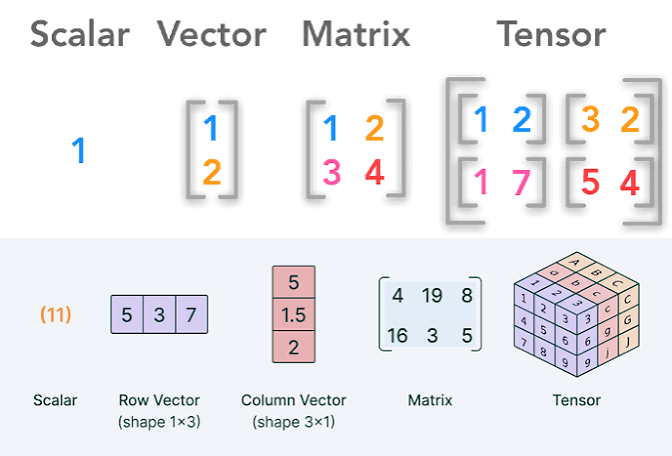

In [8]:
appareil = "cuda" if torch.cuda.is_available() else "cpu"
t = torch.tensor([[1.0, 2.0], [3.0, 4.0]])
print("Tenseur :\n", t)
print("Forme :", tuple(t.shape), "| type :", t.dtype, "| appareil :", t.device)
print("Conversion depuis NumPy :", torch.from_numpy(np.arange(3)))
print("Produit matriciel t @ t :\n", t @ t)
print("Déplacement vers", appareil, ":", t.to(appareil).device)

Tenseur :
 tensor([[1., 2.],
        [3., 4.]])
Forme : (2, 2) | type : torch.float32 | appareil : cpu
Conversion depuis NumPy : tensor([0, 1, 2])
Produit matriciel t @ t :
 tensor([[ 7., 10.],
        [15., 22.]])
Déplacement vers cpu : cpu


## 5. Autograd et rétropropagation

En IA101, le gradient de l'EQM a été dérivé à la main. Pour un réseau de millions de paramètres, ce calcul est automatisé par **autograd** : PyTorch construit le **graphe de calcul** lors de la passe avant, puis applique la règle de dérivation des fonctions composées en parcourant ce graphe **de la sortie vers les entrées**. C'est la **rétropropagation**.

### Exemple détaillé

Un réseau minimal à deux neurones en chaîne : $h = \text{ReLU}(w_1 x)$, $\hat{y} = w_2 h$, perte $L = (\hat{y} - y)^2$.

Avec $x = 2$, $y = 3$, $w_1 = 0{,}5$, $w_2 = 2$ :
- passe avant : $h = \text{ReLU}(1) = 1$, $\hat{y} = 2$, $L = 1$ ;
- passe arrière, de la sortie vers l'entrée :

$$\frac{\partial L}{\partial \hat{y}} = 2(\hat{y} - y) = -2 \qquad \frac{\partial L}{\partial w_2} = \frac{\partial L}{\partial \hat{y}}\cdot h = -2 \qquad \frac{\partial L}{\partial h} = \frac{\partial L}{\partial \hat{y}}\cdot w_2 = -4$$

$$\frac{\partial L}{\partial w_1} = \frac{\partial L}{\partial h}\cdot \text{ReLU}'(w_1 x)\cdot x = -4 \times 1 \times 2 = -8$$

Chaque gradient se calcule à partir du gradient de la couche suivante : c'est ce qui rend la rétropropagation efficace.



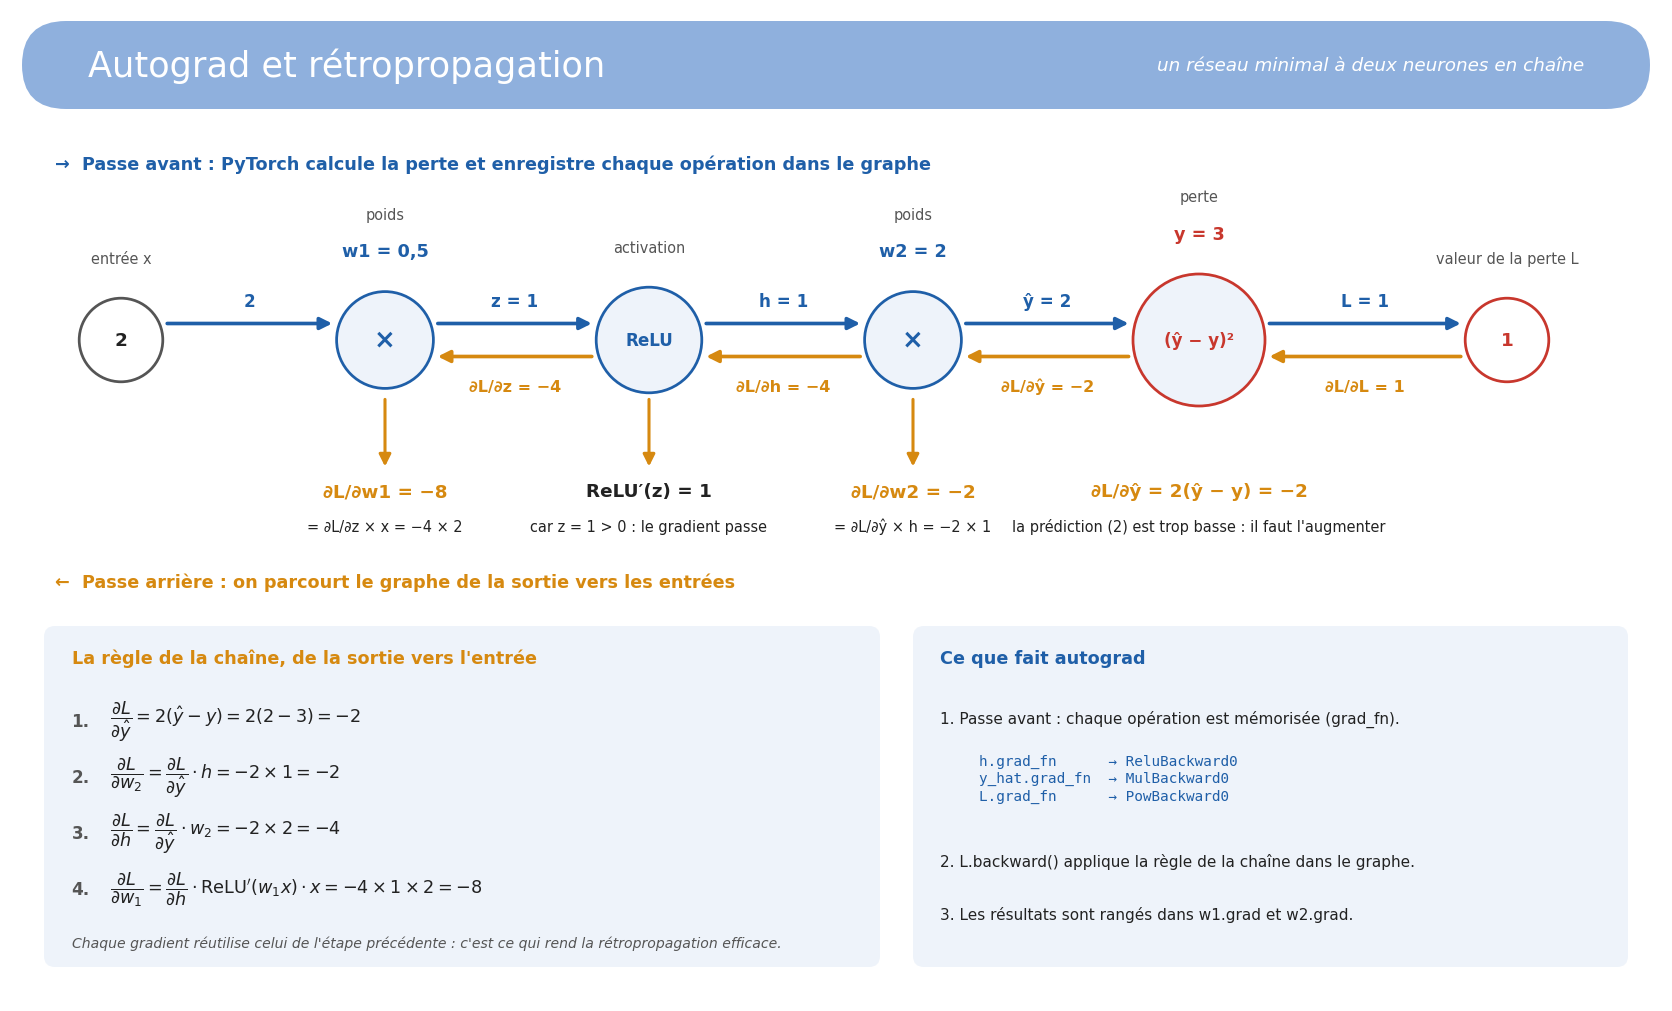

In [12]:
# @title
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Couleurs de la charte des figures
ENCRE, GRIS = "#222222", "#555555"
BLEU, BLEU_CLAIR, FOND = "#1f5fa8", "#8fb0dd", "#eef3fa"
ROUGE, ORANGE, BEIGE = "#c8372d", "#d68910", "#f4e6d7"


def nombre(v, dec=0):
    """Nombre au format français : virgule décimale et vrai signe moins."""
    return f"{v:.{dec}f}".replace(".", ",").replace("-", "−")


def fleche(ax, depart, arrivee, couleur, lw=2.4):
    ax.add_patch(FancyArrowPatch(depart, arrivee, arrowstyle="-|>", mutation_scale=16,
                                 color=couleur, lw=lw, shrinkA=0, shrinkB=0, zorder=2))


def noeud(ax, x, y, r, texte, ec, fc="white", couleur_texte=ENCRE, taille=12):
    ax.add_patch(Circle((x, y), r, fc=fc, ec=ec, lw=1.8, zorder=4))
    ax.text(x, y, texte, ha="center", va="center", fontsize=taille, fontweight="bold",
            color=couleur_texte, zorder=5)


def encadre(ax, x, y, l, h, fc=FOND):
    ax.add_patch(FancyBboxPatch((x, y), l, h, boxstyle="round,pad=0,rounding_size=1",
                                fc=fc, ec="none", zorder=1))


# Exemple : h = ReLU(w1·x), ŷ = w2·h, L = (ŷ − y)²
x, y, w1, w2 = 2.0, 3.0, 0.5, 2.0

# Passe avant
z = w1 * x                 # 1
h = max(z, 0.0)            # ReLU(1) = 1
y_hat = w2 * h             # 2
L = (y_hat - y) ** 2       # 1

# Passe arrière (règle de dérivation des fonctions composées)
dL_dyhat = 2 * (y_hat - y)          # −2
dL_dw2 = dL_dyhat * h               # −2
dL_dh = dL_dyhat * w2               # −4
relu_prime = 1.0 if z > 0 else 0.0  # ReLU'(z) = 1 car z > 0
dL_dz = dL_dh * relu_prime          # −4
dL_dw1 = dL_dz * x                  # −8

fig = plt.figure(figsize=(15, 9))
ax = fig.add_axes([0, 0, 1, 1])
ax.set_xlim(0, 150); ax.set_ylim(0, 90); ax.axis("off")

# Bandeau de titre
ax.add_patch(FancyBboxPatch((1, 81), 148, 8, boxstyle="round,pad=0,rounding_size=4", fc=BLEU_CLAIR, ec="none"))
ax.text(7, 85, "Autograd et rétropropagation", color="white", fontsize=23, va="center")
ax.text(143, 85, "un réseau minimal à deux neurones en chaîne", color="white", fontsize=12,
        va="center", ha="right", style="italic")

# Graphe de calcul : (position x, symbole, paramètre affiché, couleur, rôle, rayon)
yg = 60
noeuds = [
    (10, nombre(x), "", ENCRE, "entrée x", 3.8),
    (34, "×", f"w1 = {nombre(w1, 1)}", BLEU, "poids", 4.4),
    (58, "ReLU", "", BLEU, "activation", 4.8),
    (82, "×", f"w2 = {nombre(w2)}", BLEU, "poids", 4.4),
    (108, "(ŷ − y)²", f"y = {nombre(y)}", ROUGE, "perte", 6.0),
    (136, nombre(L), "", ROUGE, "valeur de la perte L", 3.8),
]
for xx, sym, param, c, role, r in noeuds:
    operation = role not in ("entrée x", "valeur de la perte L")
    noeud(ax, xx, yg, r, sym, ec=c if c != ENCRE else GRIS, fc=FOND if operation else "white",
          couleur_texte=c, taille=17 if sym == "×" else (11 if len(sym) > 2 else 12))
    if param:
        ax.text(xx, yg + r + 3.2, param, ha="center", fontsize=11.5, fontweight="bold", color=c)
        ax.text(xx, yg + r + 6.6, role, ha="center", fontsize=9.5, color=GRIS)
    else:
        ax.text(xx, yg + r + 3.2, role, ha="center", fontsize=9.5, color=GRIS)

# Arêtes : passe avant au-dessus (bleu), passe arrière au-dessous (orange)
bords = [(n[0] - n[5], n[0] + n[5]) for n in noeuds]   # (gauche, droite) de chaque noeud
valeurs_avant = [nombre(x), f"z = {nombre(z)}", f"h = {nombre(h)}", f"ŷ = {nombre(y_hat)}", f"L = {nombre(L)}"]
gradients = [None, f"∂L/∂z = {nombre(dL_dz)}", f"∂L/∂h = {nombre(dL_dh)}",
             f"∂L/∂ŷ = {nombre(dL_dyhat)}", "∂L/∂L = 1"]
for k in range(5):
    x1, x2 = bords[k][1] + .4, bords[k + 1][0] - .4
    fleche(ax, (x1, yg + 1.5), (x2, yg + 1.5), BLEU)
    ax.text((x1 + x2) / 2, yg + 3.1, valeurs_avant[k], ha="center", fontsize=11, fontweight="bold", color=BLEU)
    if gradients[k]:
        fleche(ax, (x2, yg - 1.5), (x1, yg - 1.5), ORANGE)
        ax.text((x1 + x2) / 2, yg - 4.6, gradients[k], ha="center", fontsize=10.5, fontweight="bold", color=ORANGE)

# Gradients des poids et dérivée de ReLU, sous les noeuds
details = [
    (34, f"∂L/∂w1 = {nombre(dL_dw1)}", f"= ∂L/∂z × x = {nombre(dL_dz)} × {nombre(x)}"),
    (58, f"ReLU′(z) = {nombre(relu_prime)}", "car z = 1 > 0 : le gradient passe"),
    (82, f"∂L/∂w2 = {nombre(dL_dw2)}", f"= ∂L/∂ŷ × h = {nombre(dL_dyhat)} × {nombre(h)}"),
]
for xx, titre, calcul in details:
    fleche(ax, (xx, yg - 5.4), (xx, yg - 11.5), ORANGE, lw=2)
    ax.text(xx, yg - 14.2, titre, ha="center", fontsize=12, fontweight="bold",
            color=ORANGE if xx != 58 else ENCRE)
    ax.text(xx, yg - 17.4, calcul, ha="center", fontsize=9.5, color=ENCRE)
ax.text(108, yg - 14.2, f"∂L/∂ŷ = 2(ŷ − y) = {nombre(dL_dyhat)}", ha="center", fontsize=12, fontweight="bold", color=ORANGE)
ax.text(108, yg - 17.4, "la prédiction (2) est trop basse : il faut l'augmenter", ha="center", fontsize=9.5, color=ENCRE)

# Légende des deux passes
ax.text(4, 75.5, "→  Passe avant : PyTorch calcule la perte et enregistre chaque opération dans le graphe",
        fontsize=11.5, fontweight="bold", color=BLEU)
ax.text(4, 37.5, "←  Passe arrière : on parcourt le graphe de la sortie vers les entrées",
        fontsize=11.5, fontweight="bold", color=ORANGE)

# Bas gauche : la règle de la chaîne, étape par étape
encadre(ax, 3, 3, 76, 31)
ax.text(5.5, 30.6, "La règle de la chaîne, de la sortie vers l'entrée", fontsize=11.5, fontweight="bold", color=ORANGE)
etapes = [
    rf"$\dfrac{{\partial L}}{{\partial \hat y}} = 2(\hat y - y) = 2(2 - 3) = {dL_dyhat:.0f}$",
    rf"$\dfrac{{\partial L}}{{\partial w_2}} = \dfrac{{\partial L}}{{\partial \hat y}}\cdot h = {dL_dyhat:.0f} \times {h:.0f} = {dL_dw2:.0f}$",
    rf"$\dfrac{{\partial L}}{{\partial h}} = \dfrac{{\partial L}}{{\partial \hat y}}\cdot w_2 = {dL_dyhat:.0f} \times {w2:.0f} = {dL_dh:.0f}$",
    rf"$\dfrac{{\partial L}}{{\partial w_1}} = \dfrac{{\partial L}}{{\partial h}}\cdot \mathrm{{ReLU}}'(w_1 x)\cdot x = {dL_dh:.0f} \times 1 \times {x:.0f} = {dL_dw1:.0f}$",
]
for i, e in enumerate(etapes):
    ax.text(5.5, 25.4 - i * 5.1, f"{i + 1}.", fontsize=11, color=GRIS, va="center", fontweight="bold")
    ax.text(9, 25.4 - i * 5.1, e.replace("-", "−").replace("−>", "->"), fontsize=11.5, color=ENCRE, va="center")
ax.text(5.5, 5.2, "Chaque gradient réutilise celui de l'étape précédente : c'est ce qui rend la rétropropagation efficace.",
        fontsize=9.2, color=GRIS, style="italic", va="center")

# Bas droite : ce que fait autograd
encadre(ax, 82, 3, 65, 31)
ax.text(84.5, 30.6, "Ce que fait autograd", fontsize=11.5, fontweight="bold", color=BLEU)
ax.text(84.5, 25.6, "1. Passe avant : chaque opération est mémorisée (grad_fn).", fontsize=10, color=ENCRE, va="center")
ax.text(88, 22.4, "h.grad_fn      → ReluBackward0\n"
                  "y_hat.grad_fn  → MulBackward0\n"
                  "L.grad_fn      → PowBackward0",
        family="monospace", fontsize=9.4, color=BLEU, va="top", linespacing=1.3)
ax.text(84.5, 12.6, "2. L.backward() applique la règle de la chaîne dans le graphe.", fontsize=10, color=ENCRE, va="center")
ax.text(84.5, 7.8, "3. Les résultats sont rangés dans w1.grad et w2.grad.", fontsize=10, color=ENCRE, va="center")

plt.savefig("fig5_retropropagation.png", dpi=170, facecolor="white")
plt.show()

### Exercice 2 — Vérifier la rétropropagation avec autograd

In [ ]:
x, y = torch.tensor(2.0), torch.tensor(3.0)
w1 = torch.tensor(0.5, requires_grad=True)
w2 = torch.tensor(2.0, requires_grad=True)

h = torch.relu(w1 * x)
y_chapeau = w2 * h
perte = (y_chapeau - y) ** 2
...                          # À COMPLÉTER : déclencher la rétropropagation avec perte.backward()

print(f"perte = {perte.item()}")
print(f"dL/dw2 = {w2.grad.item()}  (calcul à la main : -2)")
print(f"dL/dw1 = {w1.grad.item()}  (calcul à la main : -8)")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
x, y = torch.tensor(2.0), torch.tensor(3.0)
w1 = torch.tensor(0.5, requires_grad=True)
w2 = torch.tensor(2.0, requires_grad=True)

h = torch.relu(w1 * x)
y_chapeau = w2 * h
perte = (y_chapeau - y) ** 2
perte.backward()

print(f"perte = {perte.item()}")
print(f"dL/dw2 = {w2.grad.item()}  (calcul à la main : -2)")
print(f"dL/dw1 = {w1.grad.item()}  (calcul à la main : -8)")
```

</details>

```
Passe avant  :   x ──> [w1·x] ──> ReLU ──> h ──> [w2·h] ──> ŷ ──> L
Passe arrière:   ∂L/∂w1 <──────────────── ∂L/∂h <──────── ∂L/∂ŷ <── 1
```

`perte.backward()` remplit l'attribut `.grad` de chaque paramètre. La **mise à jour** des paramètres est une étape distincte, réalisée par un optimiseur (notebook 2).

## 6. Définir un réseau

### Option A — `nn.Sequential` : une pile de couches

In [8]:
modele = nn.Sequential(
    nn.Linear(4, 16),   # 4 variables d'entrée -> 16 neurones
    nn.ReLU(),
    nn.Linear(16, 3),   # 16 -> 3 sorties (une par classe)
)
print(modele)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=3, bias=True)
)


### Exercice 3 — Formes des tenseurs et nombre de paramètres

Un lot de 32 observations traverse ce réseau.

1. Quelle est la forme du tenseur après chaque couche ?
2. Combien de paramètres le réseau contient-il ? Une couche `Linear(n, m)` possède $n \times m$ poids et $m$ biais.

In [ ]:
formes_prevues = [(32, ...), (32, ...), (32, ...)]   # À COMPLÉTER
nb_parametres_prevu = ...                            # À COMPLÉTER

lot = torch.randn(32, 4)
for couche in modele:
    lot = couche(lot)
    print(f"{couche.__class__.__name__:<8} -> {tuple(lot.shape)}")
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()))

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
formes_prevues = [(32, 16), (32, 16), (32, 3)]
nb_parametres_prevu = (4 * 16 + 16) + (16 * 3 + 3)   # 80 + 51 = 131

lot = torch.randn(32, 4)
for couche in modele:
    lot = couche(lot)
    print(f"{couche.__class__.__name__:<8} -> {tuple(lot.shape)}")
print("Nombre de paramètres :", sum(p.numel() for p in modele.parameters()), "| prévu :", nb_parametres_prevu)
```

</details>

### Option B — Sous-classer `nn.Module` (recommandé)

La classe déclare ses couches dans `__init__` et décrit le calcul dans `forward`. Cette forme permet tout calcul (branches, sorties multiples, connexions résiduelles) et constitue la norme dans les projets.

In [9]:
class ClassifieurMulticouche(nn.Module):
    def __init__(self, n_entrees=4, n_caches=16, n_classes=3):
        super().__init__()
        self.couche1 = nn.Linear(n_entrees, n_caches)
        self.couche2 = nn.Linear(n_caches, n_classes)

    def forward(self, x):
        h = torch.relu(self.couche1(x))
        return self.couche2(h)

modele_b = ClassifieurMulticouche()
print(modele_b)
print("Sortie pour 5 observations :", tuple(modele_b(torch.randn(5, 4)).shape))

ClassifieurMulticouche(
  (couche1): Linear(in_features=4, out_features=16, bias=True)
  (couche2): Linear(in_features=16, out_features=3, bias=True)
)
Sortie pour 5 observations : (5, 3)


## 7. Couche de sortie et fonction de perte

| Tâche | Exemple | Couche de sortie | Fonction de perte |
| --- | --- | --- | --- |
| Régression | Délai d'arrivée | `Linear(…, 1)` | `nn.MSELoss()` |
| Classification binaire | Malin ou bénin | `Linear(…, 1)` | `nn.BCEWithLogitsLoss()` |
| Classification multiclasse | 10 catégories de vêtements | `Linear(…, 10)` | `nn.CrossEntropyLoss()` |

Avec `BCEWithLogitsLoss` et `CrossEntropyLoss`, la sigmoïde ou le softmax sont intégrés à la fonction de perte, pour des raisons de stabilité numérique : le réseau renvoie des scores bruts (*logits*).

In [ ]:
quiz("Que se passe-t-il si l'on empile dix couches Linear sans fonction d'activation ?",
     ["Le réseau devient plus expressif", "Le réseau reste équivalent à une seule couche linéaire", "L'entraînement devient impossible"],
     1, "Une composition de fonctions affines est affine : seules les activations apportent la non-linéarité.")

In [ ]:
quiz("Que fait perte.backward() ?",
     ["Il calcule la prédiction", "Il calcule le gradient de la perte par rapport à chaque paramètre", "Il met à jour les paramètres"],
     1, "backward() remplit les attributs .grad ; la mise à jour est réalisée ensuite par l'optimiseur.")

## À retenir

- **Neurone** : $a = \varphi(w^\top x + b)$ ; une **couche** applique plusieurs neurones en parallèle ; un **réseau** enchaîne des couches.
- Les **activations non linéaires** (ReLU) donnent au réseau sa capacité d'approximation.
- **Tenseurs** : tableaux qui peuvent résider sur GPU et enregistrer les opérations.
- **Rétropropagation** : application de la règle des fonctions composées de la sortie vers l'entrée ; automatisée par `backward()`.
- Définir un réseau : `nn.Sequential` ou une sous-classe de `nn.Module` (`__init__` et `forward`).

**Notebook suivant :** 2 — Entraîner un réseau avec PyTorch.